In [ ]:
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px


In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/srivatsan88/YouTubeLI/master/dataset/nyc_energy_consumption.csv')

In [ ]:
df.head()

,timeStamp,demand,precip,temp
0,2012-01-01 00:00:00,4937.5,0.0,46.13
1,2012-01-01 01:00:00,4752.1,0.0,45.89
2,2012-01-01 02:00:00,4542.6,0.0,45.04
3,2012-01-01 03:00:00,4357.7,0.0,45.03
4,2012-01-01 04:00:00,4275.5,0.0,42.61


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49205 entries, 0 to 49204
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timeStamp  49205 non-null  object 
 1   demand     49124 non-null  float64
 2   precip     48975 non-null  float64
 3   temp       49019 non-null  float64
dtypes: float64(3), object(1)
memory usage: 1.5+ MB


In [ ]:
df['timeStamp']= pd.to_datetime(df['timeStamp'])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49205 entries, 0 to 49204
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timeStamp  49205 non-null  datetime64[ns]
 1   demand     49124 non-null  float64       
 2   precip     48975 non-null  float64       
 3   temp       49019 non-null  float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 1.5 MB


In [ ]:
df.head()

,timeStamp,demand,precip,temp
0,2012-01-01 00:00:00,4937.5,0.0,46.13
1,2012-01-01 01:00:00,4752.1,0.0,45.89
2,2012-01-01 02:00:00,4542.6,0.0,45.04
3,2012-01-01 03:00:00,4357.7,0.0,45.03
4,2012-01-01 04:00:00,4275.5,0.0,42.61


plotting a line graph for timeStamp aganist demand using plotly

In [ ]:
figure = px.line(df,x='timeStamp',y='demand',title='Demand Over Time')
figure.update_xaxes(
    rangeslider_visible = True,
    rangeselector = dict(
        buttons = list([
            dict(count = 1,label = '1year',step = 'year',stepmode = 'backward'),
            dict(count = 2,label = '2years',step = 'year',stepmode = 'backward'),
            dict(count = 1,label = '3years',step = 'year',stepmode = 'backward'),
            dict(step = 'all')
        ])
    )
)
figure.show()

In [ ]:
#setting the timestamp as the index
df.set_index('timeStamp',inplace=True)

In [ ]:
df.head()

,demand,precip,temp
timeStamp,,,
2012-01-01 00:00:00,4937.5,0.0,46.13
2012-01-01 01:00:00,4752.1,0.0,45.89
2012-01-01 02:00:00,4542.6,0.0,45.04
2012-01-01 03:00:00,4357.7,0.0,45.03
2012-01-01 04:00:00,4275.5,0.0,42.61


## Data Visualization

array([<Axes: xlabel='timeStamp'>, <Axes: xlabel='timeStamp'>,
       <Axes: xlabel='timeStamp'>], dtype=object)

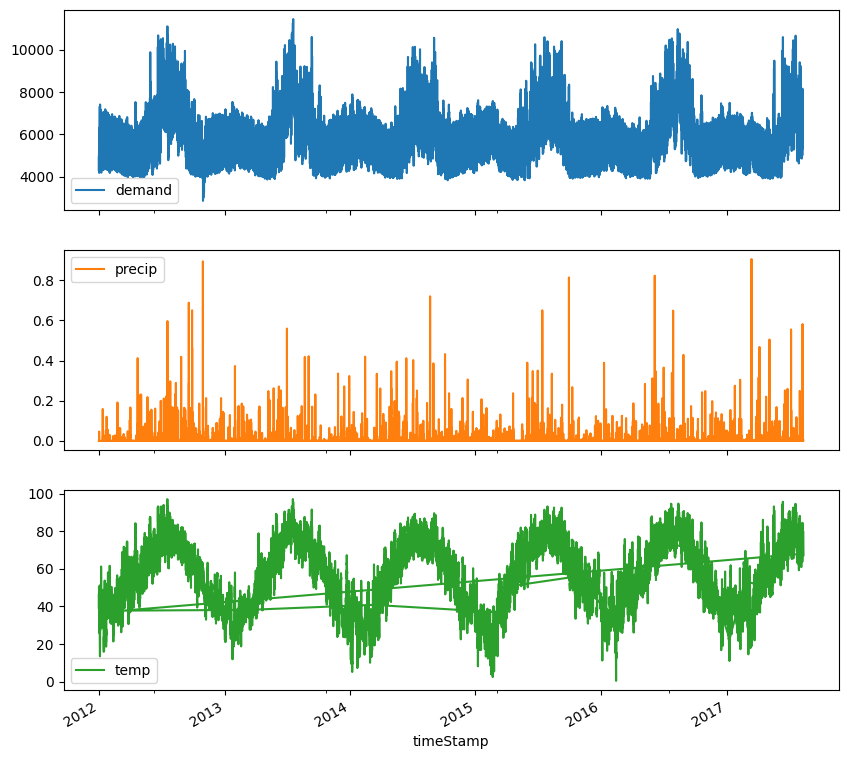

In [ ]:
df.plot(subplots=True,figsize=(10,10))

In [ ]:
# checking for the size of our dataset and the number of features
print(f'The number of observations are {df.shape[0]}')
print(f'The number of features are {df.shape[1]}')
print(df.isnull().any())

The number of observations are 49205
The number of features are 3
demand    True
precip    True
temp      True
dtype: bool


In [ ]:
df.isnull().sum()

,0
demand,81
precip,230
temp,186


Displaying the records that contain missing values

In [ ]:
df.query('demand != demand')

,demand,precip,temp
timeStamp,,,
2012-03-11 02:00:00,NaN,0.0000,37.78
2013-03-10 02:00:00,NaN,0.0000,38.18
2014-03-09 02:00:00,NaN,0.0000,40.86
2015-03-08 02:00:00,NaN,0.0000,36.96
2015-03-11 11:00:00,NaN,0.0000,49.95
...,...,...,...
2017-08-12 02:00:00,NaN,0.0000,70.84
2017-08-12 03:00:00,NaN,0.0000,70.57
2017-08-12 04:00:00,NaN,0.0000,69.89


## Handling Missing Values

In [ ]:
df['demand']= df['demand'].fillna(method = 'ffill')
df['precip'] = df['precip'].fillna(method = 'ffill')
df['temp'] = df['temp'].fillna(method = 'ffill')

<ipython-input-18-b22bd53dbcf8>:1: FutureWarning:

Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.

<ipython-input-18-b22bd53dbcf8>:2: FutureWarning:

Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.

<ipython-input-18-b22bd53dbcf8>:3: FutureWarning:

Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.



In [ ]:
df.isnull().sum()

,0
demand,0
precip,0
temp,0


There are now no missing values

## Data Resampling

In [ ]:
df.resample('M').mean()

<ipython-input-20-f6f2e5924c1f>:1: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



,demand,precip,temp
timeStamp,,,
2012-01-31,5757.495833,0.003116,37.174288
2012-02-29,5622.331609,0.001650,40.448046
2012-03-31,5479.919198,0.001179,49.607917
2012-04-30,5368.945833,0.003959,54.255903
2012-05-31,5867.896102,0.005064,64.188078
...,...,...,...
2017-04-30,5233.477382,0.002942,55.621764
2017-05-31,5421.773060,0.004031,61.115457
2017-06-30,6597.990346,0.003008,71.962625


<ipython-input-23-b30bc93ae882>:1: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



array([<Axes: xlabel='timeStamp'>, <Axes: xlabel='timeStamp'>,
       <Axes: xlabel='timeStamp'>], dtype=object)

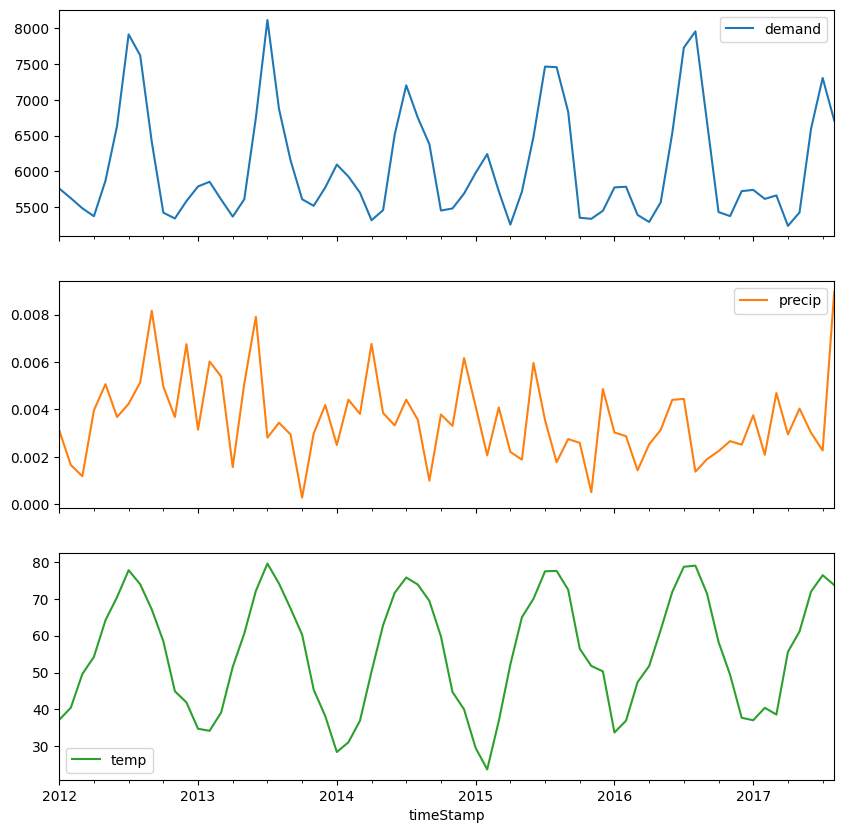

In [ ]:
df.resample('M').mean().plot(subplots=True,figsize=(10,10))

In [ ]:
df_monthly = df.resample('M').mean()

<ipython-input-24-9b9170e38d05>:1: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



## Displaying decomposition of our time series in the demand column

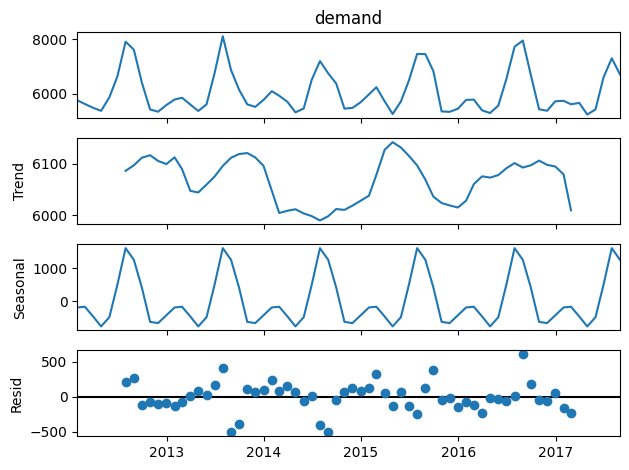

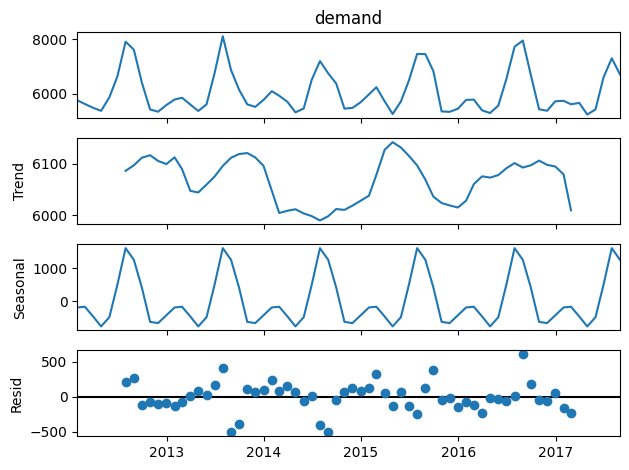

In [27]:
from statsmodels.tsa.seasonal import seasonal_decompose
figure = seasonal_decompose(df_monthly['demand'])
figure.plot()

In [28]:
! pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 22.0 MB/s eta 0:00:00


In [29]:
import pmdarima as pm
model = pm.auto_arima(df_monthly['demand'],seasonal=True,m=12,start_p=0,start_q=0,max_order=4,test='adf',error_action = 'ignore',suppress_warnings = True,stepwise = True,trace = True)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(1,0,1)[12] intercept   : AIC=inf, Time=0.80 sec
 ARIMA(0,0,0)(0,0,0)[12] intercept   : AIC=1100.321, Time=0.02 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



 ARIMA(1,0,0)(1,0,0)[12] intercept   : AIC=1023.743, Time=0.56 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : AIC=inf, Time=0.18 sec
 ARIMA(0,0,0)(0,0,0)[12]             : AIC=1380.758, Time=0.02 sec

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.




 ARIMA(1,0,0)(0,0,0)[12] intercept   : AIC=1065.516, Time=0.03 sec


... (28 outputs left out)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



 ARIMA(3,0,1)(0,0,2)[12] intercept   : AIC=999.148, Time=1.21 sec


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



 ARIMA(2,0,0)(0,0,2)[12]             : AIC=inf, Time=0.74 sec

Best model:  ARIMA(2,0,0)(0,0,2)[12] intercept
Total fit time: 19.347 seconds


In [30]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                        SARIMAX Results                                        
===============================================================================================
Dep. Variable:                                       y   No. Observations:                   68
Model:             SARIMAX(2, 0, 0)x(0, 0, [1, 2], 12)   Log Likelihood                -490.572
Date:                                 Tue, 04 Feb 2025   AIC                            993.144
Time:                                         10:02:21   BIC                           1006.461
Sample:                                     01-31-2012   HQIC                           998.420
                                          - 08-31-2017                                         
Covariance Type:                                   opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   3721.6223    792.260      4.697      0.000    2168.821    5274.423
ar.L1          0.8586      0.123      6.985      0.000       0.618       1.099
ar.L2         -0.4748      0.142     -3.352      0.001      -0.752      -0.197
ma.S.L12       0.8923      0.137      6.501      0.000       0.623       1.161
ma.S.L24       0.4571      0.206      2.222      0.026       0.054       0.860
sigma2      9.046e+04   1.58e+04      5.726      0.000    5.95e+04    1.21e+05
===================================================================================
Ljung-Box (L1) (Q):                   0.02   Jarque-Bera (JB):                 5.55
Prob(Q):                              0.89   Prob(JB):                         0.06
Heteroskedasticity (H):               0.78   Skew:                             0.52
Prob(H) (two-sided):                  0.55   Kurtosis:                         3.94
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [33]:
train = df_monthly[(df_monthly.index.get_level_values(0) >= '2012-01-31') &(df_monthly.index.get_level_values(0) <= '2017-04-30')]
test = df_monthly[df_monthly.index.get_level_values(0) > '2017-04-30']

In [34]:
print(train.shape)
print(test.shape)


(64, 3)
(4, 3)


### Fitting the ARIMA MODEL

In [35]:
model.fit(train['demand'])

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



ARIMA(order=(2, 0, 0), scoring_args={}, seasonal_order=(0, 0, 2, 12),
      suppress_warnings=True)

## Forecasting

In [40]:
forecast = model.predict(n_periods = 4,return_conf_int = True)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



In [41]:
forecast

(2017-05-31    5320.832641
 2017-06-30    6194.150520
 2017-07-31    7184.108255
 2017-08-31    7297.999709
 Freq: ME, dtype: float64,
 array([[4724.37012964, 5917.2951525 ],
        [5391.43558076, 6996.86545858],
        [6358.62011365, 8009.5963956 ],
        [6467.74947806, 8128.24994011]]))

In [42]:
forecast_df = pd.DataFrame(forecast[0],index = test.index,columns = ['Prediction'])
forecast_df

,Prediction
timeStamp,
2017-05-31,5320.832641
2017-06-30,6194.150520
2017-07-31,7184.108255
2017-08-31,7297.999709


Joining our prediction to the original data frame

<Axes: xlabel='timeStamp'>

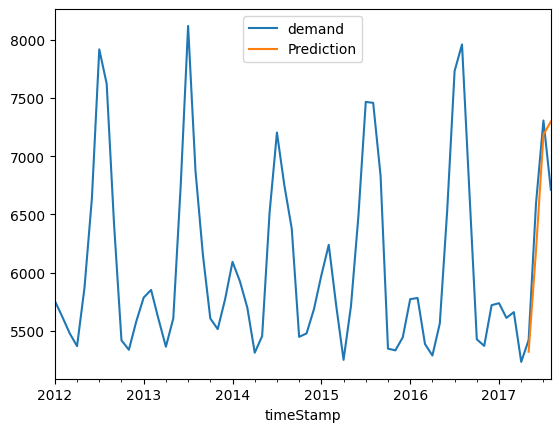

In [43]:
pd.concat([df_monthly['demand'],forecast_df],axis = 1).plot()

Increasing the time period to 8 months for prediction

In [46]:
forecast1 = model.predict(n_periods = 8,return_conf_int = True)
forecast1

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.



(2017-05-31    5320.832641
 2017-06-30    6194.150520
 2017-07-31    7184.108255
 2017-08-31    7297.999709
 2017-09-30    6401.927265
 2017-10-31    5789.924167
 2017-11-30    5693.039547
 2017-12-31    5951.573040
 Freq: ME, dtype: float64,
 array([[4724.37012964, 5917.2951525 ],
        [5391.43558076, 6996.86545858],
        [6358.62011365, 8009.5963956 ],
        [6467.74947806, 8128.24994011],
        [5553.64732299, 7250.20720672],
        [4934.10749926, 6645.74083498],
        [4837.0853228 , 6548.99377166],
        [5094.94718002, 6808.19889933]]))

In [47]:
forecast_range = pd.date_range(start = '2017-05-31',periods = 8 ,freq = 'M')
forecast1_df = pd.DataFrame(forecast1[0],index = forecast_range,columns = ['Prediction'])
forecast1_df

<ipython-input-47-5aafa87c0636>:1: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



,Prediction
2017-05-31,5320.832641
2017-06-30,6194.150520
2017-07-31,7184.108255
2017-08-31,7297.999709
2017-09-30,6401.927265
2017-10-31,5789.924167
2017-11-30,5693.039547
2017-12-31,5951.573040


<Axes: >

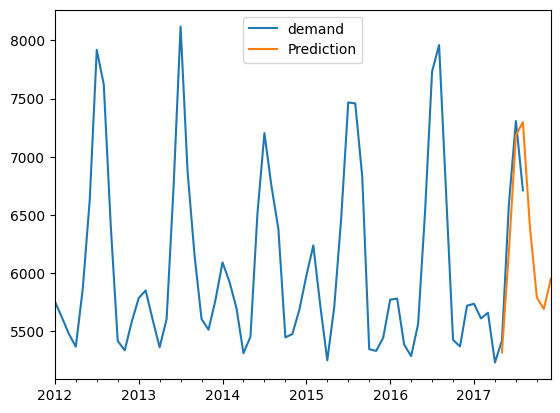

In [48]:
pd.concat([df_monthly['demand'],forecast1_df],axis = 1).plot()

In [50]:
# Instead of using 'forecast' which contains prediction for 4 months
# We should use 'forecast1' which contains prediction for 8 months
lower = pd.Series(forecast1[1][:,0],index = forecast_range)
upper = pd.Series(forecast1[1][:,1],index = forecast_range)

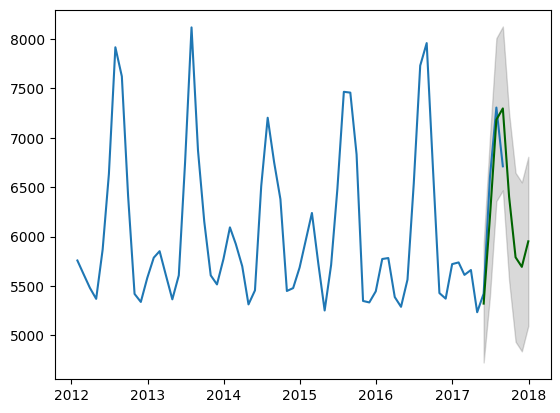

In [51]:
plt.plot(df_monthly['demand'],label = 'Actual')
plt.plot(forecast1_df['Prediction'],label = 'Predicted',color = 'darkgreen')
plt.fill_between(forecast_range,lower,upper,color='k',alpha =0.15)
plt.show()

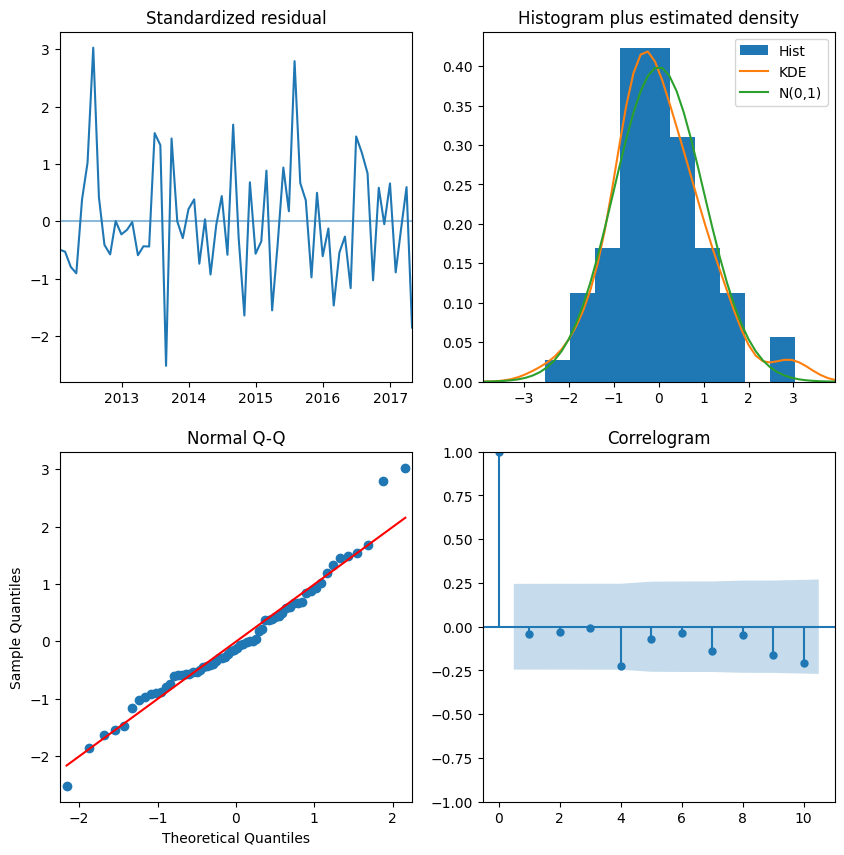

In [53]:
out = model.plot_diagnostics(figsize=(10,10))